# Дополнительные материалы: Weight Dropout для рекуррентных сетей

> **Дополнительный материал к лабораторной работе № 5.** Этот раздел не является обязательной частью основной лабораторной работы. Он показывает один из способов экспериментировать с регуляризацией рекуррентных моделей и объясняет связанные с ним особенности реализации в PyTorch.

Бо́льшая часть кода ниже дублирует работу № 5. При этом в дополнительной части рассматриваются несколько новых аспектов:

- **Особенности переобучения RNN.** Обсуждается, почему рекуррентные модели часто сильно переобучаются и почему стандартный Dropout между слоями не всегда помогает решить эту проблему.
- **Регуляризация между моментами времени.** Рассматривается идея применения Dropout непосредственно к рекуррентным связям, включая `recurrent_dropout` в TensorFlow и особенности отсутствия аналогичного стандартного параметра в PyTorch.
- **Особенности реализации RNN в PyTorch.** Объясняется, как использование cuDNN ускоряет обучение рекуррентных сетей, почему для этого важно непрерывное расположение весов в памяти и какую роль играет метод `flatten_parameters()`.
- **Weight Dropout.** Рассматривается альтернативный подход к регуляризации, при котором Dropout применяется непосредственно к весам рекуррентных связей. Также разбирается реализация такого подхода с помощью `torch.nn.utils.parametrize`, позволяющая сохранить совместимость с оптимизацией через cuDNN.
- **Сравнение нескольких конфигураций.** Проводится обучение и сравнение трёх моделей с разными значениями Dropout, включая базовую конфигурацию из основной лабораторной работы, вариант со средней регуляризацией (`0.3 / 0.3`) и вариант с усиленной регуляризацией (`0.5 / 0.5`).

[Перейти к основной части](#main)

In [ ]:
# Проверяем версии библиотек и выбираем устройство, на котором будут выполняться вычисления.
import sys
import platform
import torch

# Сначала фиксируем версии среды: это помогает понять, какие возможности PyTorch и CUDA доступны.
print(f"Python: {sys.version.split()[0]}")
print(f"Платформа: {platform.platform()}")
print(f"PyTorch: {torch.__version__}")
print(f"CUDA доступна: {torch.cuda.is_available()}")
print(f"CUDA-сборка PyTorch: {torch.version.cuda}")

# Выбираем единое устройство для дальнейших вычислений; при отсутствии CUDA используем CPU.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Устройство для вычислений: {device}")

# Дополнительные сведения о видеокарте выводим только тогда, когда CUDA действительно доступна.
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"CUDA-устройств: {torch.cuda.device_count()}")

In [2]:
# Фиксируем seed и задаём основные гиперпараметры эксперимента в одном месте.
import random
import numpy as np

SEED = 42
BATCH_SIZE = 128
MAX_EPOCHS = 10
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

In [3]:
# Загружаем AG News и разбиваем на train/validation/test.
from datasets import load_dataset


ds = load_dataset("wangrongsheng/ag_news", split="train+test")

train_test = ds.train_test_split(
    train_size=50_000,
    test_size=10_000,
    seed=SEED,
    stratify_by_column="label",
)

train_validation = train_test["train"].train_test_split(
    train_size=40_000,
    test_size=10_000,
    seed=SEED,
    stratify_by_column="label",
)

train = train_validation["train"]
validation = train_validation["test"]
test = train_test["test"]

In [4]:
# Реализуем простой словарь: частотный отбор, специальные токены, кодирование и декодирование.
from collections import Counter
import re


class Vocabulary:
    """Словарь токенов с поддержкой PAD и UNK."""

    def __init__(self, max_size: int = 30_000, min_freq: int = 2) -> None:
        self.max_size = max_size
        self.min_freq = min_freq

        self.pad_token = "<PAD>"
        self.unk_token = "<UNK>"
        self.stoi = {
            self.pad_token: 0,
            self.unk_token: 1,
        }
        self.itos = [self.pad_token, self.unk_token]

    def tokenize(self, text: str) -> list[str]:
        """Разбивает строку на lowercase-токены из букв и цифр."""
        return re.findall(r"\b\w+\b", text.lower())

    def build(self, texts) -> None:
        """Строит словарь по коллекции текстов."""
        counter = Counter()
        for text in texts:
            counter.update(self.tokenize(text))

        words = [
            (word, frequency)
            for word, frequency in counter.most_common()
            if frequency >= self.min_freq and word not in self.stoi
        ]
        words = words[: self.max_size - len(self.stoi)]

        for word, _ in words:
            self.stoi[word] = len(self.itos)
            self.itos.append(word)

    def encode(self, text: str) -> list[int]:
        """Преобразует текст в индексы; пустой текст кодируется как UNK."""
        tokens = self.tokenize(text)
        if not tokens:
            return [self.unk_idx]
        return [self.stoi.get(token, self.unk_idx) for token in tokens]

    def decode(self, token_ids: list[int]) -> list[str]:
        """Преобразует индексы обратно в токены."""
        return [self.itos[index] for index in token_ids]

    def __len__(self) -> int:
        return len(self.itos)

    @property
    def pad_idx(self) -> int:
        return self.stoi[self.pad_token]

    @property
    def unk_idx(self) -> int:
        return self.stoi[self.unk_token]

In [5]:
# Строим словарь только по обучающим текстам и проверяем несколько преобразований.
MAX_VOCAB_SIZE = 30_000
MIN_FREQ = 2
MAX_LENGTH = 160

vocab = Vocabulary(max_size=MAX_VOCAB_SIZE, min_freq=MIN_FREQ)
vocab.build(train["text"])

In [6]:
# Создаём Dataset, который хранит закодированные последовательности и метки классов.
from torch.utils.data import Dataset, DataLoader


class EncodedTextDataset(Dataset):
    """Тексты AG News, предварительно преобразованные в последовательности индексов."""

    def __init__(self, split, vocabulary: Vocabulary, max_length: int) -> None:
        self.sequences = []
        self.labels = torch.as_tensor(split["label"], dtype=torch.long)

        for text in split["text"]:
            token_ids = vocabulary.encode(text)[:max_length]
            if not token_ids:
                token_ids = [vocabulary.unk_idx]
            self.sequences.append(torch.tensor(token_ids, dtype=torch.long))

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        return self.sequences[index], self.labels[index]


train_dataset = EncodedTextDataset(train, vocab, MAX_LENGTH)
validation_dataset = EncodedTextDataset(validation, vocab, MAX_LENGTH)
test_dataset = EncodedTextDataset(test, vocab, MAX_LENGTH)

In [7]:
# Объединяем последовательности разной длины в батч и сохраняем их настоящие длины.
from typing import TypeAlias
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence

# Один элемент батча: изображение и соответствующая ему метка.
TensorPair: TypeAlias = tuple[torch.Tensor, torch.Tensor]


def collate_padded(batch: list[TensorPair]) -> tuple[TensorPair, torch.Tensor]:
    sequences, labels = zip(*batch)
    lengths = torch.tensor(
        [sequence.numel() for sequence in sequences], dtype=torch.long
    )

    tokens = pad_sequence(
        sequences,
        batch_first=True,
        padding_value=vocab.pad_idx,
    )
    labels = torch.stack(labels).long()

    return (tokens, lengths), labels

In [8]:
# Создаём DataLoader.
train_sequence_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=torch.Generator().manual_seed(SEED),
    num_workers=0,
    collate_fn=collate_padded,
    pin_memory=torch.cuda.is_available(),
)
validation_sequence_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_padded,
    pin_memory=torch.cuda.is_available(),
)
test_sequence_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    collate_fn=collate_padded,
    pin_memory=torch.cuda.is_available(),
)

<a id="main" name="main"></a>

## Почему рекуррентные модели часто переобучаются

В экспериментах лабораторной работы можно заметить, что RNN-, LSTM- и GRU-модели нередко очень быстро подстраиваются под обучающую выборку, тогда как качество на validation перестаёт улучшаться или ухудшается. Это не обязательно означает ошибку в реализации.

У рекуррентной модели достаточно большая репрезентативная способность: обучаемые embedding, рекуррентные матрицы, несколько слоёв и классификационная голова совместно подбирают представление последовательности. При этом модель многократно использует одни и те же рекуррентные преобразования на временных шагах и может запоминать характерные сочетания токенов и особенности обучающих примеров. На небольшом или относительно однотипном датасете это легко приводит к разрыву между train- и validation-метриками.

### Почему обычный Dropout между слоями может быть недостаточен

Параметр `dropout` у `nn.RNN`, `nn.GRU` и `nn.LSTM` в PyTorch применяется между выходами соседних рекуррентных слоёв, но не после последнего слоя. Для однослойной RNN этот параметр фактически не даёт эффекта. Даже в многослойной модели такой Dropout не затрагивает рекуррентные матрицы, которые отвечают за перенос информации от одного временного шага к следующему.

Поэтому желание регуляризовать именно рекуррентное преобразование выглядит естественно: можно попытаться вносить случайные пропуски не только в представления между слоями, но и в связи, по которым скрытое состояние переносится во времени.

### Dropout между временными шагами: `recurrent_dropout`

В TensorFlow/Keras у рекуррентных слоёв есть отдельный аргумент `recurrent_dropout`. Он задаёт Dropout для рекуррентных соединений, то есть для преобразования предыдущего скрытого состояния. Это ближе к идее регуляризации повторяющегося во времени перехода, чем обычный Dropout между слоями.

У стандартных `nn.RNN`, `nn.GRU` и `nn.LSTM` в PyTorch отдельного аргумента `recurrent_dropout` нет. Поэтому напрямую перенести такую настройку из Keras в PyTorch нельзя: требуется собственная ячейка/реализация или другой способ регуляризации рекуррентных весов.

## cuDNN и скорость рекуррентных слоёв

На CUDA PyTorch может использовать оптимизированные реализации рекуррентных слоёв на основе **cuDNN**. Они существенно ускоряют вычисления, но для их использования должны выполняться некоторые требования. В частности, веса рекуррентного слоя должны быть доступны в подходящем формате и размещаться в согласованной непрерывной области памяти.

Для этого у `nn.RNNBase` (базового класса для `nn.RNN`, `nn.GRU` и `nn.LSTM`) предусмотрен метод `flatten_parameters()`. Он пытается расположить веса в едином плоском буфере, чтобы cuDNN мог эффективно их использовать. Обычно PyTorch вызывает его автоматически в подходящих ситуациях, например при инициализации и переносе слоя на устройство; при необходимости его можно вызвать явно.

Однако изменение способа доступа к параметрам может помешать PyTorch распознать исходный набор весов как подходящий для cuDNN. Это важно учитывать при реализации нестандартной регуляризации: дополнительная регуляризация может улучшить качество обучения, но одновременно снизить скорость вычислений.

In [9]:
from typing import Any

import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils import parametrize


class _WeightDropout(nn.Module):
    """
    Модуль Weight Dropout для регуляризации матриц весов.

    Применяет Dropout непосредственно к переданному тензору весов,
    не изменяя исходный обучаемый параметр.

    Используется совместно с механизмом параметризаций PyTorch,
    который автоматически применяет преобразование при обращении
    к соответствующему параметру.

    Args:
        p: Вероятность зануления элементов матрицы весов.
    """

    def __init__(self, p: float = 0.2):
        super().__init__()

        if not 0.0 <= p < 1.0:
            raise ValueError(
                "Вероятность Weight Dropout должна находиться в диапазоне [0, 1)."
            )

        self.p = p

    def forward(self, weight: torch.Tensor) -> torch.Tensor:
        """
        Применяет Dropout к переданной матрице весов.

        В режиме обучения генерирует новую маску Dropout.
        В режиме оценки возвращает исходные веса без изменений.

        Args:
            weight: Исходная обучаемая матрица весов.

        Returns:
            Матрица весов с применённым Dropout.
        """
        return F.dropout(weight, p=self.p, training=self.training)


class WeightDropout(nn.Module):
    """
    Модуль Weight Dropout для произвольной нейронной сети.

    Применяет Dropout непосредственно к выбранным параметрам весов,
    используя механизм параметризаций PyTorch.

    Исходные параметры сохраняются в качестве обучаемых параметров,
    а их преобразованные представления автоматически используются
    моделью во время прямого прохода.

    Поддерживает выбор одного или нескольких параметров,
    а также автоматический выбор всех параметров весов.

    Args:
        model: Экземпляр нейронной сети.
        p: Вероятность зануления элементов матриц весов.
        weights: Имя параметра, список имён параметров или None.
            None означает применение Weight Dropout ко всем весам.
    """

    def __init__(
        self,
        model: nn.RNNBase,
        p: float = 0.2,
        weights: str | list[str] | None = None,
    ):
        super().__init__()

        if not isinstance(model, nn.RNNBase):
            raise TypeError("Модель должна быть экземпляром nn.RNNBase.")

        if not 0.0 <= p < 1.0:
            raise ValueError(
                "Вероятность Weight Dropout должна находиться в диапазоне [0, 1)."
            )

        self.model = model
        self.p = p

        # Собираем имена всех обучаемых параметров модели.
        self.parameter_names = [
            name for name, _ in self.model.named_parameters(recurse=False)
        ]

        # Собираем имена всех параметров весов.
        self.available_weights = [
            name for name in self.parameter_names if name.startswith("weight_hh_")
        ]

        # Определяем параметры, к которым будет применяться Weight Dropout.
        if weights is None:
            self.weight_names = self.available_weights.copy()
        elif isinstance(weights, str):
            self.weight_names = [weights]
        elif isinstance(weights, list):
            self.weight_names = list(dict.fromkeys(weights))
        else:
            raise TypeError(
                "Аргумент weights должен быть строкой, списком строк или None."
            )

        # Проверяем корректность переданных имён параметров.
        for name in self.weight_names:
            if not isinstance(name, str):
                raise TypeError("Все элементы weights должны быть строками.")

            if name not in self.available_weights:
                raise ValueError(
                    f"Параметр '{name}' отсутствует среди весов модели. "
                    f"Доступные веса: {self.available_weights}."
                )

        # Регистрируем параметризацию для каждой выбранной матрицы весов.
        # Исходные параметры остаются обучаемыми, а при обращении
        # к ним автоматически применяется Weight Dropout.
        if p > 0:
            for name in self.weight_names:
                parametrize.register_parametrization(
                    self.model, name, _WeightDropout(p)
                )

        # Преобразуем имена параметров при сохранении и загрузке state_dict,
        # сохраняя совместимость с исходной моделью PyTorch.
        self.register_state_dict_post_hook(self._state_dict_hook)
        self.register_load_state_dict_pre_hook(self._load_state_dict_hook)

    def forward(
        self,
        input: torch.Tensor,
        hx: torch.Tensor | TensorPair | None = None,
    ) -> TensorPair | tuple[torch.Tensor, TensorPair]:
        """
        Выполняет прямой проход через рекуррентный слой.

        Использует кэширование результатов параметризации, чтобы
        преобразованные матрицы весов вычислялись один раз за вызов
        рекуррентного слоя и повторно использовались при обращении к ним.

        Args:
            input: Входной тензор последовательности.
            hx: Начальное скрытое состояние. Для LSTM передаётся кортеж
                из скрытого состояния и состояния ячейки.

        Returns:
            Кортеж из выходного тензора и последнего скрытого состояния.
            Для LSTM последнее скрытое состояние представляет собой
            кортеж из двух тензоров.
        """
        with parametrize.cached():
            return self.model(input, hx)

    @staticmethod
    def _state_dict_hook(
        module: nn.Module,
        state_dict: dict[str, torch.Tensor],
        prefix: str,
        *args: Any,
        **kwargs: Any,
    ) -> None:
        """
        Преобразует имена параметров при сохранении state_dict.

        Заменяет имена исходных параметров параметризаций
        `parametrizations.weight.original` на стандартные имена
        `weight`, обеспечивая совместимость сохранённого словаря
        с исходной моделью PyTorch.

        Args:
            module: Модуль, для которого вызывается хук.
            state_dict: Словарь сохраняемых параметров модели.
            prefix: Префикс имён параметров текущего модуля.
            *args: Дополнительные позиционные аргументы хука.
            **kwargs: Дополнительные именованные аргументы хука.
        """
        if not isinstance(module, WeightDropout):
            return

        for name in module.parameter_names:
            if name in module.weight_names and module.p > 0:
                source = f"{prefix}model.parametrizations.{name}.original"
            else:
                source = f"{prefix}model.{name}"

            target = f"{prefix}{name}"

            if source in state_dict:
                state_dict[target] = state_dict.pop(source)

    @staticmethod
    def _load_state_dict_hook(
        module: nn.Module,
        state_dict: dict[str, torch.Tensor],
        prefix: str,
        *args: Any,
        **kwargs: Any,
    ) -> None:
        """
        Преобразует имена параметров перед загрузкой state_dict.

        Заменяет стандартные имена `weight` на имена исходных
        параметров параметризаций `parametrizations.weight.original`,
        позволяя загружать веса исходных моделей PyTorch
        в модели с Weight Dropout.

        Args:
            module: Модуль, для которого вызывается хук.
            state_dict: Словарь загружаемых параметров модели.
            prefix: Префикс имён параметров текущего модуля.
            *args: Дополнительные позиционные аргументы хука.
            **kwargs: Дополнительные именованные аргументы хука.
        """
        if not isinstance(module, WeightDropout):
            return

        for name in module.parameter_names:
            source = f"{prefix}{name}"

            if name in module.weight_names and module.p > 0:
                target = f"{prefix}model.parametrizations.{name}.original"
            else:
                target = f"{prefix}model.{name}"

            if source in state_dict:
                state_dict[target] = state_dict.pop(source)

## Weight Dropout: регуляризация самих рекуррентных весов

Один из вариантов регуляризации рекуррентного перехода - **Weight Dropout**. Вместо зануления элементов входного или выходного представления он применяет Dropout непосредственно к матрице весов. В этой реализации регуляризуются матрицы `weight_hh_*`, то есть веса, участвующие в преобразовании предыдущего скрытого состояния.

Идея состоит в том, чтобы во время обучения использовать случайно разреженную версию рекуррентной матрицы. Веса при этом не удаляются навсегда: маска Dropout применяется в режиме обучения, а в режиме оценки используются исходные значения параметров.

### Почему здесь используется `torch.nn.utils.parametrize`

Можно было бы вручную заменять параметр весов перед каждым прямым проходом, но такой подход усложняет работу с оптимизатором и сохранением состояния модели. Механизм `parametrize` позволяет зарегистрировать преобразование параметра: исходный обучаемый тензор остаётся параметром модели, а при обращении к нему автоматически возвращается преобразованная версия.

Таким образом, оптимизатор продолжает обновлять исходные веса, а Weight Dropout применяется как параметризация. Внутри `forward` дополнительно используется `parametrize.cached()`: преобразованные веса кэшируются на время одного вызова рекуррентного слоя, чтобы повторные обращения к параметрам в рамках этого вызова не создавали новые маски.

**Замечание о производительности.** Параметризация создаёт преобразованное представление весов; PyTorch при каждом прямом проходе проверяет адреса весов в памяти GPU и в случае отличия автоматически вызывает `flatten_parameters()`. Дополнительное преобразование параметров требует времени (порядка 10-15% от времени прямого прохода): это компромисс между экспериментальной регуляризацией и скоростью обучения.

In [20]:
class GRUTextClassifier(nn.Module):
    """Классификатор AG News на GRU."""

    def __init__(
        self,
        vocab_size: int,
        num_classes: int,
        pad_idx: int,
        embedding_dim: int = 128,
        hidden_size: int = 128,
        num_layers: int = 2,
        dropout: float = 0.3,
        weight_dropout: float = 0.3,
        bidirectional: bool = True,
    ) -> None:
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.num_directions = 2 if bidirectional else 1

        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)

        self.gru = WeightDropout(
            model=nn.GRU(
                input_size=embedding_dim,
                hidden_size=hidden_size,
                num_layers=num_layers,
                batch_first=True,
                bidirectional=bidirectional,
                dropout=dropout if num_layers > 1 else 0.0,
            ),
            p=weight_dropout,
        )

        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size * self.num_directions, num_classes)

    def forward(self, tokens: torch.Tensor, lengths: torch.Tensor) -> torch.Tensor:
        embedded = self.embedding(tokens)
        packed = pack_padded_sequence(
            embedded,
            lengths.detach().to("cpu"),
            batch_first=True,
            enforce_sorted=False,
        )

        _, hidden = self.gru(packed)

        hidden = hidden.view(
            self.num_layers,
            self.num_directions,
            tokens.size(0),
            self.hidden_size,
        )
        last_layer = hidden[-1]
        document_vector = last_layer.transpose(0, 1).reshape(tokens.size(0), -1)

        return self.classifier(self.dropout(document_vector))

In [ ]:
%pip install lightning -qU

In [11]:
import os
import sys

sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

In [12]:
# Переопределим _shared_step и forward.
from templates.lit import LitModel


class TextClassifierLitModel(LitModel):
    def _shared_step(
        self, batch: tuple[list[torch.Tensor], torch.Tensor]
    ) -> torch.Tensor:
        """Выполняет общий прямой проход и вычисляет loss"""

        inputs, labels = batch
        logits = self(*inputs)
        loss = self.criterion(logits, labels)
        accuracy = (logits.argmax(dim=1) == labels).float().mean()

        return loss, accuracy

    def forward(self, *args: torch.Tensor) -> torch.Tensor:
        """Возвращает логиты модели для входного батча."""
        return self.model(*args)

## Сравнение трёх конфигураций регуляризации

Обучим три одинаковые по архитектуре GRU-модели, меняя только вероятности обычного Dropout и Weight Dropout:

1. `dropout=0.3`, `weight_dropout=0` - обычный Dropout между слоями и в классификационной голове, без Weight Dropout.
2. `dropout=0.3`, `weight_dropout=0.3` - **baseline из основной лабораторной работы**.
3. `dropout=0.5`, `weight_dropout=0.5` - более сильная регуляризация обоих типов.

Во всех трёх случаях сохраняются одинаковые данные, архитектура, seed и параметры обучения. Поэтому сравнение позволяет оценить именно влияние выбранных коэффициентов регуляризации. После обучения посмотрим отдельно на динамику loss и accuracy для train и validation.

In [ ]:
# Обучаем gru с разными значениями dropout и weight_dropout.

gru_results = {}

configs = [
    (0.3, 0),
    (0.3, 0.3),
    (0.5, 0.5),
]

for dropout, weight_dropout in configs:
    gru_lit = TextClassifierLitModel(
        model=GRUTextClassifier,
        vocab_size=len(vocab),
        num_classes=4,
        pad_idx=vocab.pad_idx,
        dropout=dropout,
        weight_dropout=weight_dropout,
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        seed=SEED,
    )

    gru_metrics = gru_lit.fit(
        train_loader=train_sequence_loader,
        validation_loader=validation_sequence_loader,
        epochs=MAX_EPOCHS,
        patience=MAX_EPOCHS,
    )

    # Сохраняем метрики каждой конфигурации.
    gru_results[(dropout, weight_dropout)] = gru_metrics.groupby("epoch")[
        ["train_loss", "train_accuracy", "val_loss", "val_accuracy"]
    ].last()

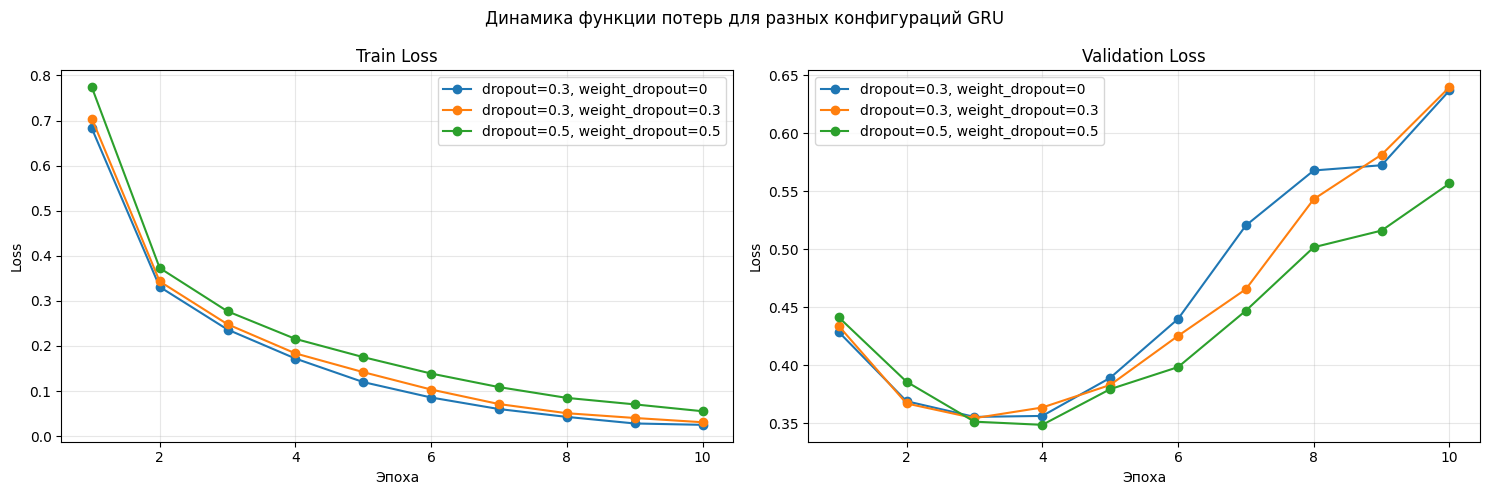

In [28]:
from matplotlib import pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for config, metrics in gru_results.items():
    label = f"dropout={config[0]}, weight_dropout={config[1]}"
    epochs = metrics.index + 1

    axes[0].plot(epochs, metrics["train_loss"], marker="o", label=label)

    axes[1].plot(epochs, metrics["val_loss"], marker="o", label=label)

axes[0].set(xlabel="Эпоха", ylabel="Loss", title="Train Loss")

axes[1].set(xlabel="Эпоха", ylabel="Loss", title="Validation Loss")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle("Динамика функции потерь для разных конфигураций GRU")
plt.tight_layout()
plt.show()

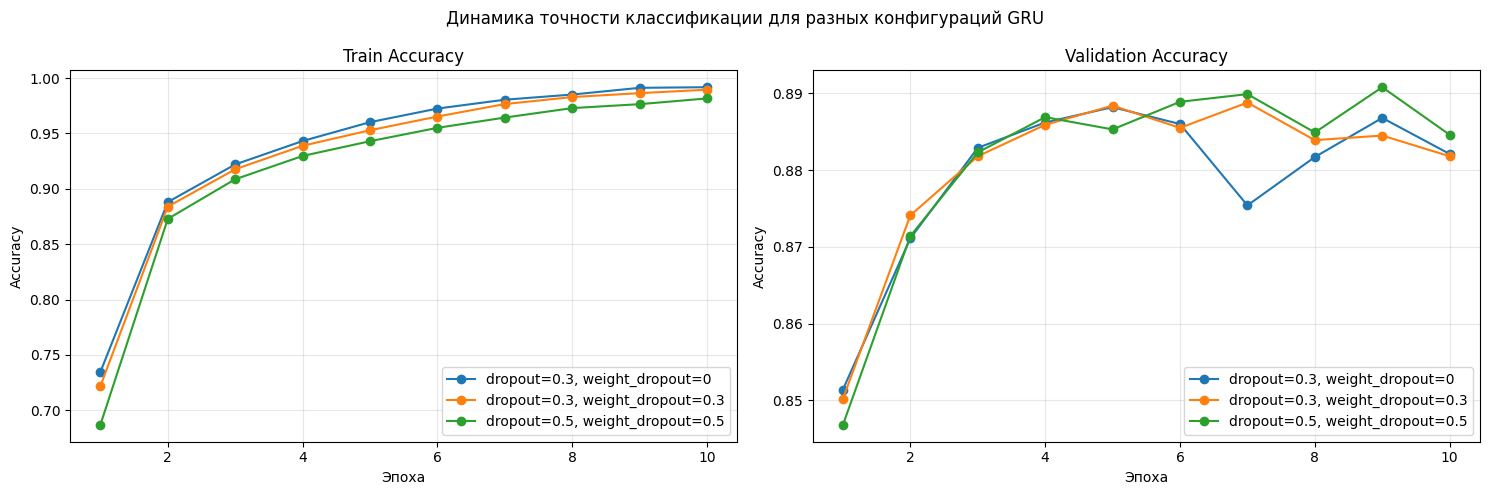

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for config, metrics in gru_results.items():
    label = f"dropout={config[0]}, weight_dropout={config[1]}"
    epochs = metrics.index + 1

    axes[0].plot(epochs, metrics["train_accuracy"], marker="o", label=label)

    axes[1].plot(epochs, metrics["val_accuracy"], marker="o", label=label)

axes[0].set(xlabel="Эпоха", ylabel="Accuracy", title="Train Accuracy")

axes[1].set(xlabel="Эпоха", ylabel="Accuracy", title="Validation Accuracy")

for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()

fig.suptitle("Динамика точности классификации для разных конфигураций GRU")
plt.tight_layout()
plt.show()

### **Как интерпретировать результаты**

Среди трёх рассмотренных вариантов наилучшие результаты показала конфигурация с `dropout=0.5` и `weight_dropout=0.5`. Тем не менее полностью устранить переобучение не удалось: разница между обучающими и валидационными метриками по-прежнему сохраняется.

Несмотря на положительный результат эксперимента, **Weight Dropout не получил широкого распространения в практических проектах и преимущественно встречается в научных исследованиях**. 
В большинстве практических случаев для контроля переобучения может быть достаточно настройки размера модели, обычного Dropout, weight decay, объёма обучающей выборки и количества эпох. 

Применение Weight Dropout оправдано только в том случае, если оно действительно улучшает качество модели на валидационных данных. В противном случае дополнительная регуляризация может привести к недообучению, усложнить реализацию и настройку модели, а также увеличить вычислительные затраты. Поэтому использовать его целесообразно только при наличии подтверждённой экспериментами пользы.